# Compare feature transformations - multi-seed experiment

Every model variant is trained for several random seeds. All plots show the mean over seeds,
with a shaded band / error bar for the standard deviation.

In [1]:
import gc
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[0]
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)
from tensorflow import keras
from modules.features import HolisticLandmarksFeatureExtracter, FeatureTransformer
from modules.image_annotators import RealLifeTestAnnotator
from modules.model_factory import (SimpleModel,
                                  SimpleModelWithNoise,
                                  SimpleLSTMModel)
from modules.features.transformations import (FeatureWeights,
                                              FeatureCentering,
                                              FeatureNormalizer,
                                              FeatureRemoveLegData,
                                              FeatureRemoveZCoordinates)

from modules.utilities import load_dataset, transform_dataset, transform_datasets
from modules.process import train_and_validate_model

In [2]:
DATA_PATH: Path = PROJECT_ROOT / 'mp_data'
DATA_PATH_VALIDATION: Path = PROJECT_ROOT / 'mp_data_validation'
DATA_PATH_TEST: Path = PROJECT_ROOT / 'mp_data_new_test'

# TODO: record test data
TEST_DATA_PATH: Path = PROJECT_ROOT / 'mp_data_new_test'
TENSORFLOW_MODEL_PATH: Path = Path('./output_models/simple_model.keras')
NR_OF_EPOCHS: int = 50

# Seeds used for the repeated experiment (more seeds = smoother averages, but longer runtime)
SEEDS = [42, 43, 44, 45, 46]

feature_extracter = HolisticLandmarksFeatureExtracter()

feature_transformer_none = FeatureTransformer()
feature_transformer_normalized = FeatureTransformer([FeatureNormalizer()])
feature_transformer_weighted = FeatureTransformer([FeatureWeights(10.0, 10.0, 2.0, 0.5)])
feature_transformer_centered = FeatureTransformer([FeatureCentering()])
feature_transformer_no_z_index = FeatureTransformer([FeatureRemoveZCoordinates()])
feature_transformer_leg_removal = FeatureTransformer([FeatureRemoveLegData()])
feature_transformer_all = FeatureTransformer([FeatureRemoveLegData(), FeatureRemoveZCoordinates(), FeatureNormalizer(), FeatureCentering(), FeatureWeights(10.0, 10.0, 2.0, 0.5)])

model_factory = SimpleModel()

In [3]:
# load data
raw_data, labels, actions = load_dataset(DATA_PATH,
                                             feature_extracter=feature_extracter)

raw_validation, validation_labels, actions_validation = load_dataset(DATA_PATH_VALIDATION,
                                                feature_extracter=feature_extracter)

normalized_data, normalized_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_normalized)
weighted_data, weighted_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_weighted)
centered_data, centered_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_centered)
no_z_index_data, no_z_index_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_no_z_index)
no_leg_data, no_leg_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_leg_removal)

all_transformations_data, all_transformations_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_all)

In [4]:
def train_models(seed: int = 42):

    baseline_model, baseline_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=raw_data,
                            train_labels=labels,
                            validation_dataset=raw_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS,
                            seed=seed)

    normalized_model, normalized_training = train_and_validate_model(model_factory=model_factory,
                                actions=actions,
                                train_dataset=normalized_data,
                                train_labels=labels,
                                validation_dataset=normalized_validation,
                                validation_labels=validation_labels,
                                nr_of_epochs=NR_OF_EPOCHS,
                                seed=seed)

    weighted_model, weighted_training = train_and_validate_model(model_factory=model_factory,
                                actions=actions,
                                train_dataset=weighted_data,
                                train_labels=labels,
                                validation_dataset=weighted_validation,
                                validation_labels=validation_labels,
                                nr_of_epochs=NR_OF_EPOCHS,
                                seed=seed)

    centered_model, centered_training = train_and_validate_model(model_factory=model_factory,
                                actions=actions,
                                train_dataset=centered_data,
                                train_labels=labels,
                                validation_dataset=centered_validation,
                                validation_labels=validation_labels,
                                nr_of_epochs=NR_OF_EPOCHS,
                                seed=seed)

    no_z_index_model, no_z_index_training = train_and_validate_model(model_factory=model_factory,
                                actions=actions,
                                train_dataset=no_z_index_data,
                                train_labels=labels,
                                validation_dataset=no_z_index_validation,
                                validation_labels=validation_labels,
                                nr_of_epochs=NR_OF_EPOCHS,
                                seed=seed)

    no_leg_model, no_leg_training = train_and_validate_model(model_factory=model_factory,
                                actions=actions,
                                train_dataset=no_leg_data,
                                train_labels=labels,
                                validation_dataset=no_leg_validation,
                                validation_labels=validation_labels,
                                nr_of_epochs=NR_OF_EPOCHS,
                                seed=seed)

    all_transformations_model, all_transformations_training = train_and_validate_model(model_factory=model_factory,
                                actions=actions,
                                train_dataset=all_transformations_data,
                                train_labels=labels,
                                validation_dataset=all_transformations_validation,
                                validation_labels=validation_labels,
                                nr_of_epochs=NR_OF_EPOCHS,
                                seed=seed)

    return (
           (baseline_model, baseline_training),
           (normalized_model, normalized_training),
           (weighted_model, weighted_training),
           (centered_model, centered_training),
           (no_z_index_model, no_z_index_training),
           (no_leg_model, no_leg_training),
           (all_transformations_model, all_transformations_training)
    )

# Prepare the independent test set

The test set is loaded and transformed once. Every transformed variant is evaluated by its own model, in every seed run.

In [5]:
def class_indices(y):
    y = np.asarray(y)
    return np.argmax(y, axis=1) if y.ndim > 1 and y.shape[-1] > 1 else y.reshape(-1)


def predictions(model, x):
    return np.argmax(model.predict(x, verbose=0), axis=1)


test_raw, test_labels, test_actions = load_dataset(
    DATA_PATH_TEST,
    feature_extracter=feature_extracter
)

# Ensure class indices have the same meaning for both datasets
assert list(test_actions) == list(actions), (
    f"Class mismatch: training={actions}, test={test_actions}"
)

# Must be in the same order as the tuple returned by train_models()
MODEL_NAMES = ["Baseline", "Normalized", "Weighted", "Centered", "No Z Index", "No Leg Data", "All Transformations"]

test_inputs = {
    "Baseline": test_raw,
    "Normalized": transform_dataset(test_raw, feature_transformer=feature_transformer_normalized),
    "Weighted": transform_dataset(test_raw, feature_transformer=feature_transformer_weighted),
    "Centered": transform_dataset(test_raw, feature_transformer=feature_transformer_centered),
    "No Z Index": transform_dataset(test_raw, feature_transformer=feature_transformer_no_z_index),
    "No Leg Data": transform_dataset(test_raw, feature_transformer=feature_transformer_leg_removal),
    "All Transformations": transform_dataset(test_raw, feature_transformer=feature_transformer_all),
}

y_true = class_indices(test_labels)

# Run the experiment for multiple seeds

For every seed, all model variants are trained and evaluated on the test set.
Only the Keras history and the test metrics are kept, so memory does not grow with the number of seeds.

In [6]:
labels_idx = np.arange(len(actions))

histories = {name: [] for name in MODEL_NAMES}   # per seed: Keras history dict
test_runs = {name: [] for name in MODEL_NAMES}   # per seed: test metrics

for seed in SEEDS:
    print(f"\n######## SEED {seed} ########")
    keras.backend.clear_session()  # avoid growing memory / tf.function retracing across runs

    trained = train_models(seed=seed)

    for name, (model, training) in zip(MODEL_NAMES, trained):
        y_pred = predictions(model, test_inputs[name])
        report = classification_report(
            y_true,
            y_pred,
            labels=labels_idx,
            target_names=actions,
            output_dict=True,
            zero_division=0
        )

        histories[name].append(training.history)
        test_runs[name].append({
            "Seed": seed,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
            "Macro F1": report["macro avg"]["f1-score"],
            "F1 per class": np.array([report[a]["f1-score"] for a in actions]),
            "Confusion matrix": confusion_matrix(y_true, y_pred, labels=labels_idx),
        })

    # free the models of this seed before the next one
    del trained
    gc.collect()


######## SEED 42 ########
Actions: ['idle', 'poes', 'slapen', 'vogel']
Number of sequences: 120
Number of classes: 4
Input shape: (120, 30, 1659)
Input dtype: float32
NaN values: 0
Infinite values: 0
Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 225ms/step - categorical_accuracy: 0.1917 - loss: 1.4540 - val_categorical_accuracy: 0.2500 - val_loss: 1.4287
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - categorical_accuracy: 0.1917 - loss: 1.4893 - val_categorical_accuracy: 0.2500 - val_loss: 1.3701
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - categorical_accuracy: 0.3500 - loss: 1.3969 - val_categorical_accuracy: 0.3167 - val_loss: 1.3677
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - categorical_accuracy: 0.2833 - loss: 1.3918 - val_categorical_accuracy: 0.4500 - val_loss: 1.3143
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - categorical_accuracy: 0.3500 - loss: 1.3384 - val_categorical_accuracy: 0.5000 - val_loss: 1.2378
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - 

# Aggregate the results over seeds

In [7]:
def stack_history(name, key):
    """Return an (n_seeds, n_epochs) array for a Keras history key."""
    return np.array([h[key] for h in histories[name]])


summary = {}
for name in MODEL_NAMES:
    runs = test_runs[name]
    summary[name] = {
        metric: (np.mean([r[metric] for r in runs]), np.std([r[metric] for r in runs]))
        for metric in ["Accuracy", "Balanced accuracy", "Macro F1"]
    }
    summary[name]["F1 per class"] = (
        np.mean([r["F1 per class"] for r in runs], axis=0),
        np.std([r["F1 per class"] for r in runs], axis=0),
    )
    summary[name]["Confusion matrix"] = np.mean([r["Confusion matrix"] for r in runs], axis=0)

print(f"Test results over {len(SEEDS)} seeds (mean ± std)")
print("=" * 90)
for name in MODEL_NAMES:
    s = summary[name]
    print(
        f"{name:20s} "
        f"accuracy={s['Accuracy'][0]:.3f}±{s['Accuracy'][1]:.3f}  "
        f"balanced_acc={s['Balanced accuracy'][0]:.3f}±{s['Balanced accuracy'][1]:.3f}  "
        f"macro_F1={s['Macro F1'][0]:.3f}±{s['Macro F1'][1]:.3f}"
    )

print("\nBaseline vs. all transformations (mean difference over seeds)")
for metric in ["Accuracy", "Balanced accuracy", "Macro F1"]:
    base = summary["Baseline"][metric][0]
    full = summary["All Transformations"][metric][0]
    print(f"{metric:20s}: Baseline={base:.3f}, All transformations={full:.3f}, Difference={(full - base) * 100:+.2f} pp")

Test results over 5 seeds (mean ± std)
Baseline             accuracy=0.468±0.029  balanced_acc=0.468±0.029  macro_F1=0.461±0.023
Normalized           accuracy=0.583±0.077  balanced_acc=0.583±0.077  macro_F1=0.594±0.071
Weighted             accuracy=0.617±0.037  balanced_acc=0.617±0.037  macro_F1=0.613±0.039
Centered             accuracy=0.608±0.061  balanced_acc=0.608±0.061  macro_F1=0.607±0.063
No Z Index           accuracy=0.467±0.045  balanced_acc=0.467±0.045  macro_F1=0.458±0.041
No Leg Data          accuracy=0.483±0.028  balanced_acc=0.483±0.028  macro_F1=0.475±0.023
All Transformations  accuracy=0.667±0.025  balanced_acc=0.667±0.025  macro_F1=0.673±0.024

Baseline vs. all transformations (mean difference over seeds)
Accuracy            : Baseline=0.468, All transformations=0.667, Difference=+19.83 pp
Balanced accuracy   : Baseline=0.468, All transformations=0.667, Difference=+19.83 pp
Macro F1            : Baseline=0.461, All transformations=0.673, Difference=+21.21 pp


In [8]:
# Per-seed test accuracy, to inspect the spread between runs
print(f"{'Model':20s}" + "".join(f"{'seed ' + str(s):>10s}" for s in SEEDS))
for name in MODEL_NAMES:
    print(f"{name:20s}" + "".join(f"{r['Accuracy']:10.3f}" for r in test_runs[name]))

Model                  seed 42   seed 43   seed 44   seed 45   seed 46
Baseline                 0.417     0.500     0.458     0.483     0.483
Normalized               0.492     0.675     0.533     0.542     0.675
Weighted                 0.608     0.658     0.550     0.625     0.642
Centered                 0.708     0.558     0.650     0.575     0.550
No Z Index               0.492     0.442     0.392     0.517     0.492
No Leg Data              0.475     0.492     0.433     0.508     0.508
All Transformations      0.692     0.675     0.633     0.692     0.642


# Training and validation curves per epoch (mean ± std over seeds)

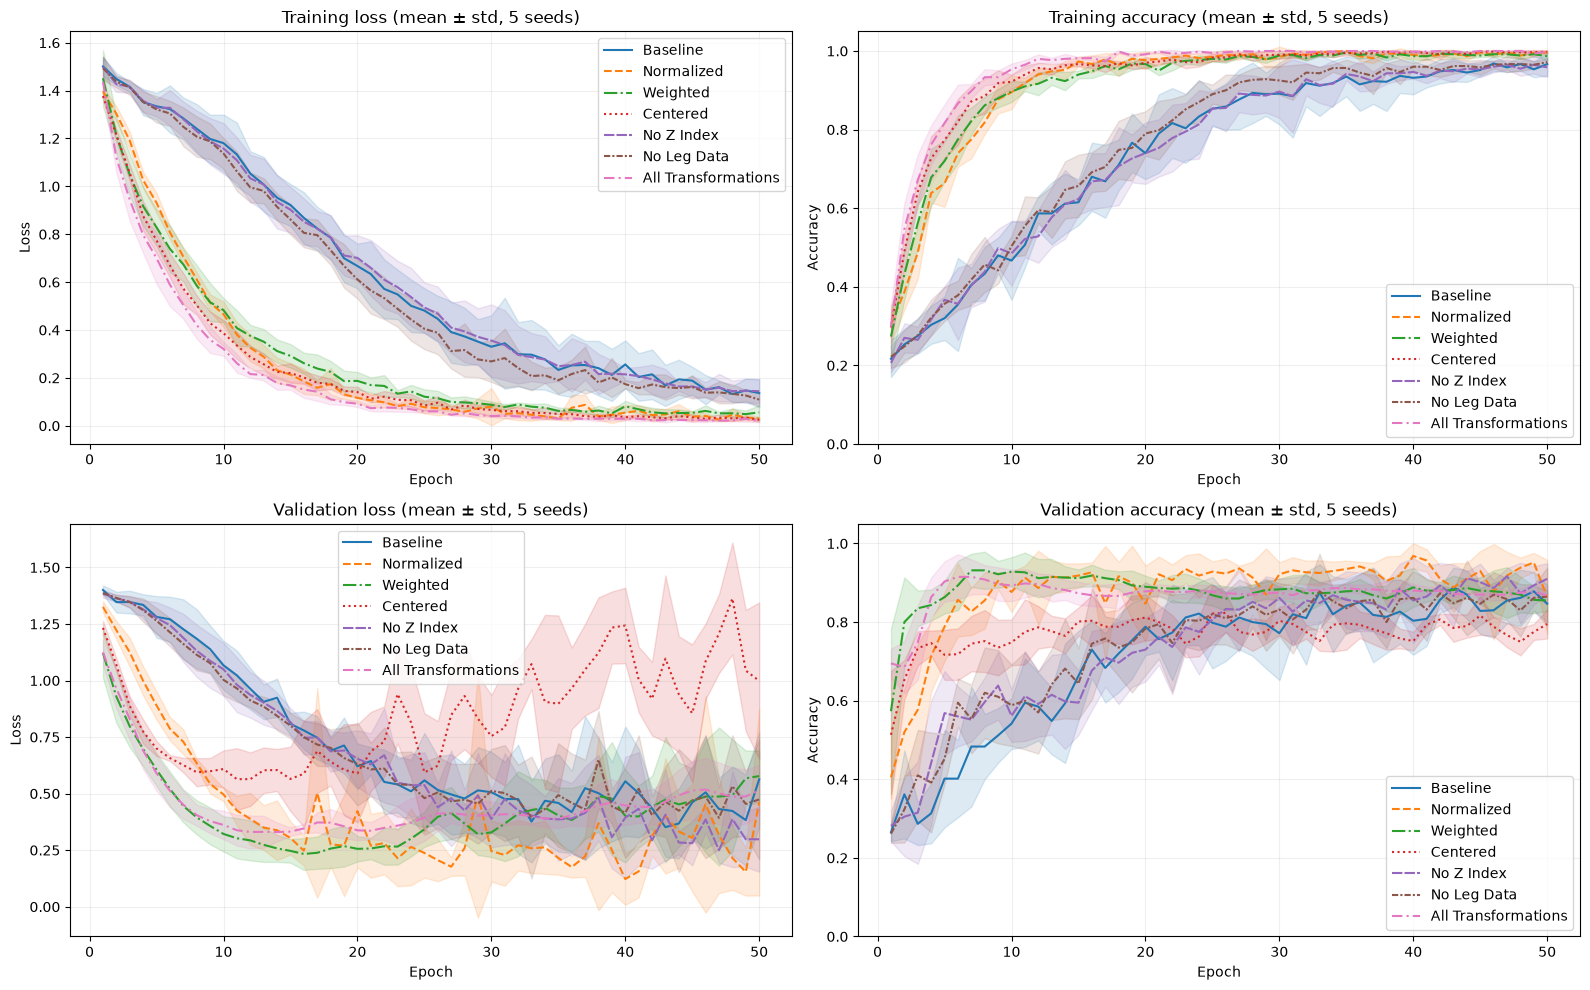

In [9]:
linestyles = ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1)), (0, (5, 2, 1, 2))]

panels = [
    ("loss", "Training loss", "Loss", None),
    ("categorical_accuracy", "Training accuracy", "Accuracy", (0, 1.05)),
    ("val_loss", "Validation loss", "Loss", None),
    ("val_categorical_accuracy", "Validation accuracy", "Accuracy", (0, 1.05)),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, (key, title, ylabel, ylim) in zip(axes.flatten(), panels):
    for name, linestyle in zip(MODEL_NAMES, linestyles):
        data = stack_history(name, key)
        mean, std = data.mean(axis=0), data.std(axis=0)
        epochs = np.arange(1, len(mean) + 1)

        line, = ax.plot(epochs, mean, label=name, linestyle=linestyle)
        ax.fill_between(epochs, mean - std, mean + std, alpha=0.15, color=line.get_color())

    ax.set(title=f"{title} (mean ± std, {len(SEEDS)} seeds)", xlabel="Epoch", ylabel=ylabel)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Confusion matrices (mean over seeds)

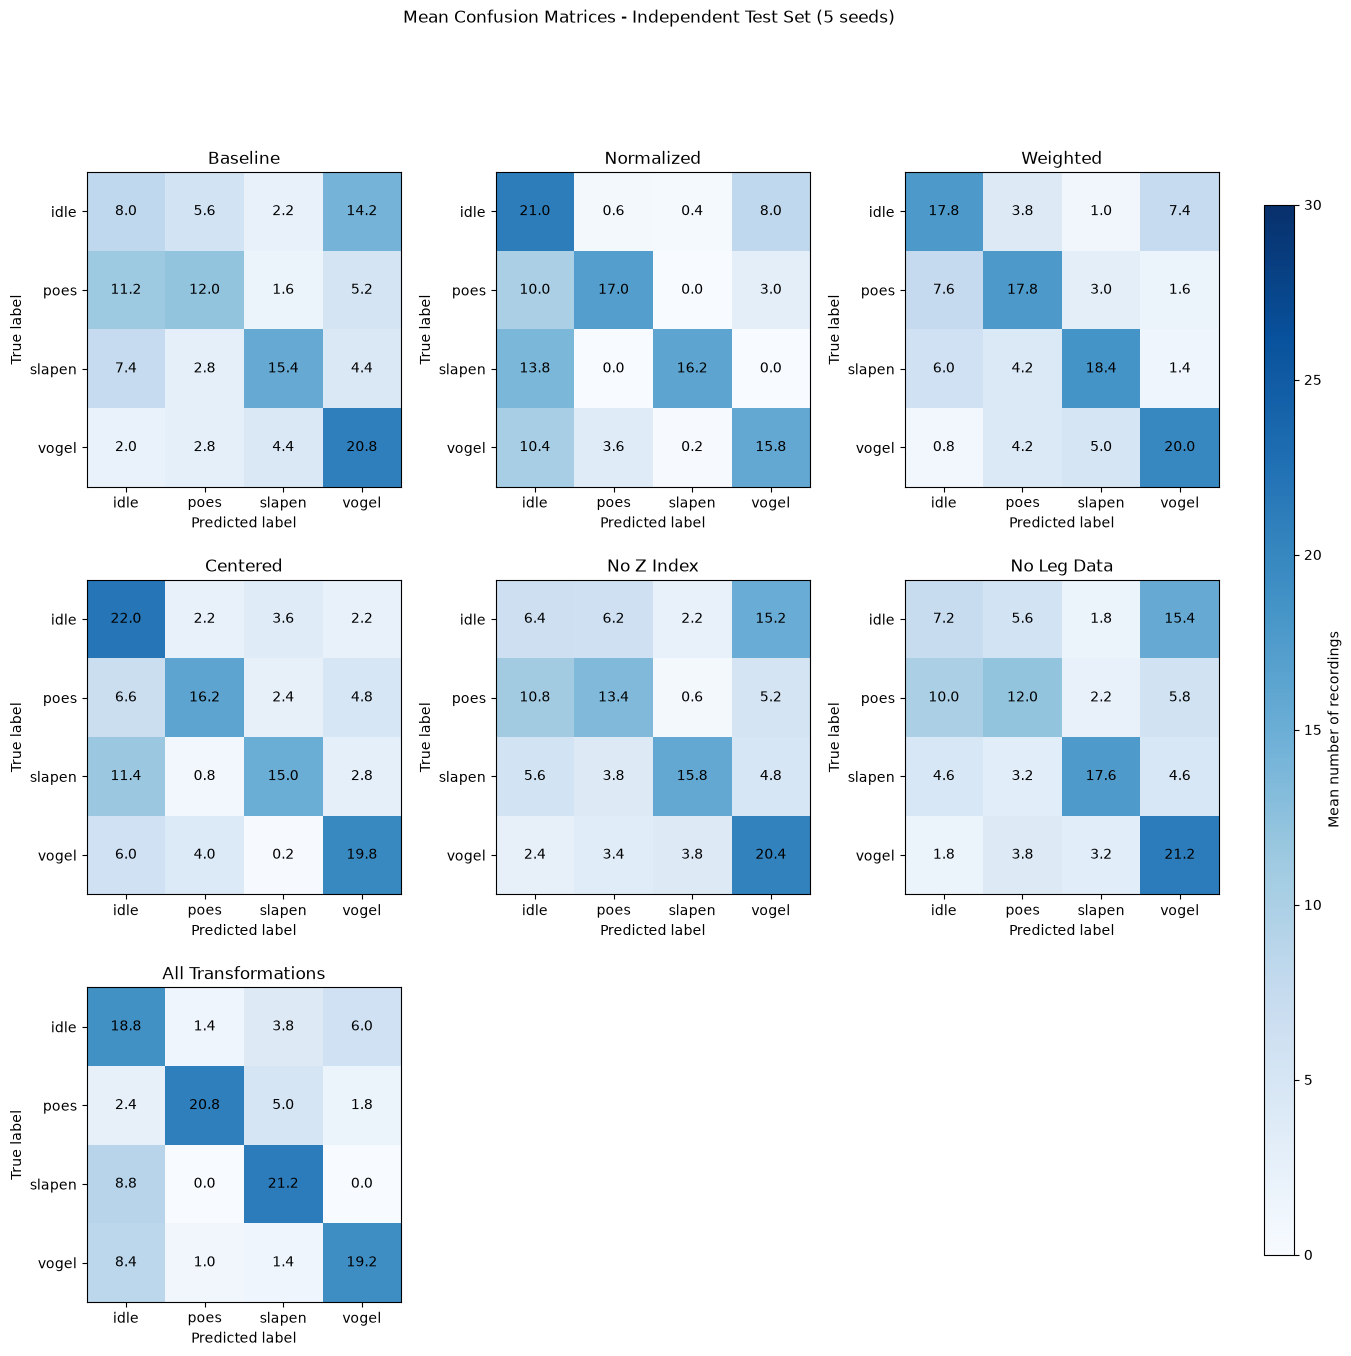

In [10]:
n_models = len(MODEL_NAMES)
n_cols = min(n_models, 3)
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(5 * n_cols, 5 * n_rows),
    squeeze=False
)

axes = axes.flatten()

for ax, name in zip(axes, MODEL_NAMES):
    cm = summary[name]["Confusion matrix"]

    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=30)

    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(len(actions)), actions)
    ax.set_yticks(range(len(actions)), actions)

    for i in range(len(actions)):
        for j in range(len(actions)):
            ax.text(j, i, f"{cm[i, j]:.1f}", ha="center", va="center")

# remove unused axes (otherwise it shows an empty confusion matrix)
for i in range(n_models, len(axes)):
    fig.delaxes(axes[i])

fig.subplots_adjust(right=0.88, wspace=0.3)
cbar_ax = fig.add_axes([0.91, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax, label="Mean number of recordings")

fig.suptitle(f"Mean Confusion Matrices - Independent Test Set ({len(SEEDS)} seeds)")
plt.show()

# Test metrics (mean ± std over seeds)

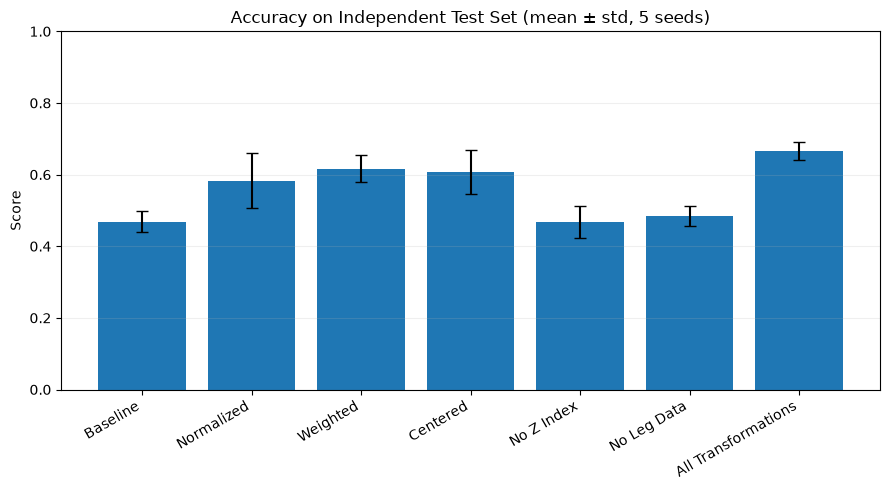

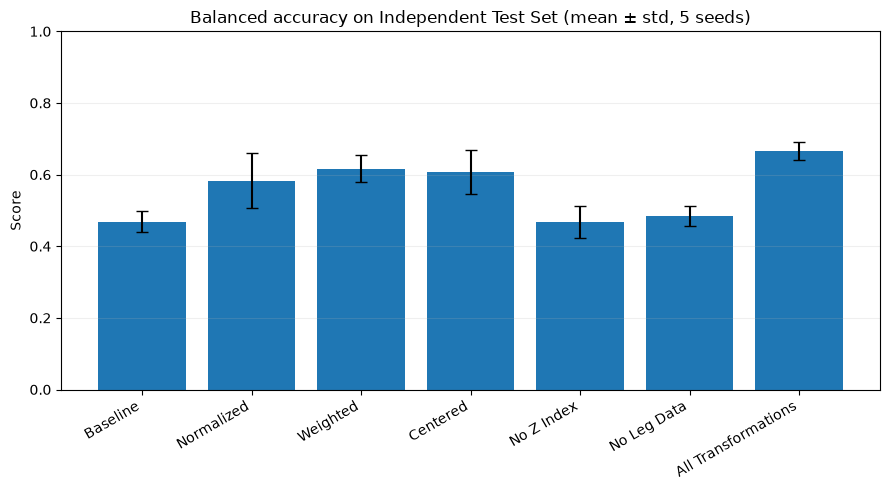

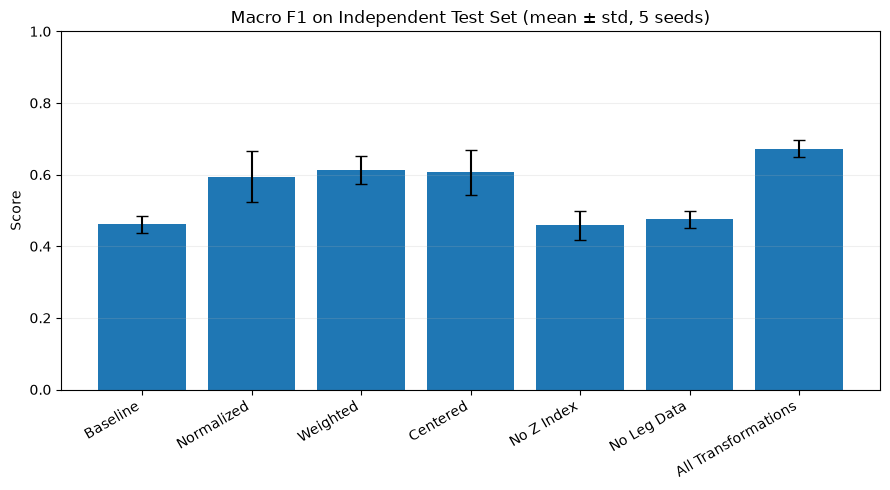

In [11]:
for metric in ["Accuracy", "Balanced accuracy", "Macro F1"]:
    means = [summary[name][metric][0] for name in MODEL_NAMES]
    stds = [summary[name][metric][1] for name in MODEL_NAMES]

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.bar(MODEL_NAMES, means, yerr=stds, capsize=4)

    ax.set_ylabel("Score")
    ax.set_title(f"{metric} on Independent Test Set (mean ± std, {len(SEEDS)} seeds)")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.2)

    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

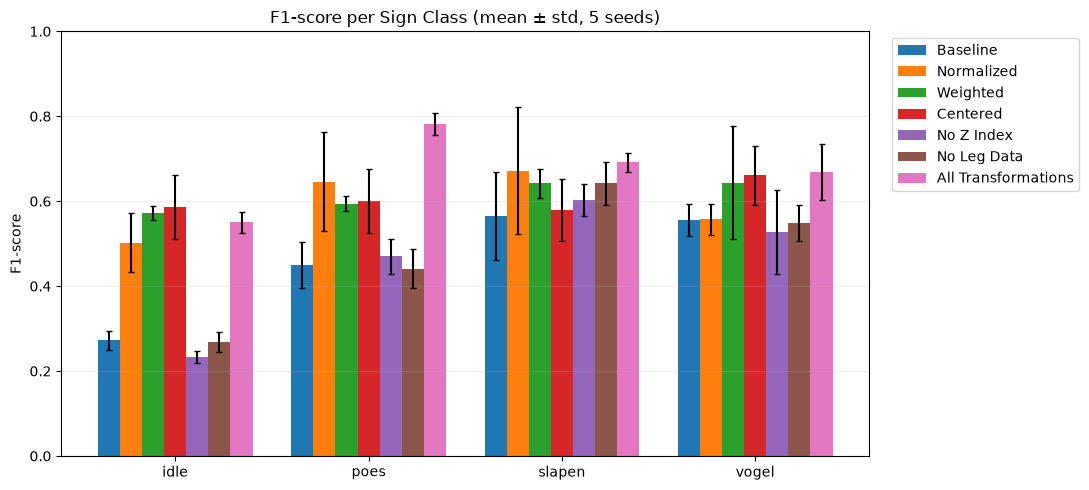

In [12]:
# Compare F1-score per sign class
x = np.arange(len(actions))
width = 0.8 / len(MODEL_NAMES)

fig, ax = plt.subplots(figsize=(11, 5))

for i, name in enumerate(MODEL_NAMES):
    mean, std = summary[name]["F1 per class"]

    ax.bar(
        x - 0.4 + width / 2 + i * width,
        mean,
        width,
        yerr=std,
        capsize=2,
        label=name
    )

ax.set_ylabel("F1-score")
ax.set_title(f"F1-score per Sign Class (mean ± std, {len(SEEDS)} seeds)")
ax.set_xticks(x)
ax.set_xticklabels(actions)
ax.set_ylim(0, 1)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()